# Fase 6: impacto na rede em 2030

Quanto a MMGD reduz a carga que a rede do Sudeste vê ao meio-dia em 2030, em cada cenário da regra de 2029?

A conta tem três partes, todas por hora:

$$\text{carga líquida}_t = \text{carga global}_t - \underbrace{\text{MW instalados}_t \times \beta_{UF,h} \times \text{radiação}_t}_{\text{geração da MMGD}}$$

1. **Geração:** os caminhos de potência instalada da fase 5 (por UF e cenário) vezes a radiação horária do INMET, com o fator
   $\beta$ calibrado na geração de MMGD que o ONS estima. O clima de 2030 é sorteado dos anos 2021–2025.
2. **Carga global:** a carga que o ONS mede *com* a MMGD (consumo total), projetada até 2030 por um modelo de série temporal
   escolhido por validação cruzada (FPP3 §5.10, cap. 8 e 9), com o perfil horário do mesmo ano do clima.
3. **Carga líquida:** a diferença. Ela nunca parte da carga líquida do ONS, que já desconta a MMGD estimada: isso descontaria
   a MMGD duas vezes.

Entradas: `cenarios_2030_caminhos.parquet` (fase 5), `ons_carga_horaria.parquet`, `inmet_horario_por_uf.parquet` e
`aneel_serie_mensal_uf.parquet`. Os dois horários (ONS e INMET) têm rótulo no fim da hora; aqui tudo passa para o **início** da
hora, em horário de Brasília, então "12h" é 12h–13h.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import norm
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from statsmodels.tsa.statespace.sarimax import SARIMAX

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import estilo
from estilo import CORES_UF, UFS

%matplotlib inline
estilo.aplicar()
warnings.simplefilter("ignore")
pd.set_option("display.precision", 3)

RES = ROOT / "resultados"
PROC = ROOT / "data" / "processed"
TZ = "America/Sao_Paulo"
AREAS = UFS + ["SUDESTE"]
CORES = {**CORES_UF, "SUDESTE": estilo.TINTA}
N = 1000                                   # caminhos usados, dos 4.000 da fase 5
ANOS_CLIMA = [2021, 2022, 2023, 2024, 2025]
MEIO_DIA = 12                              # hora de início: 12h–13h


def hora_local(s):
    """Rótulo UTC no fim da hora -> início da hora em horário de Brasília (sem horário de verão desde 2019)."""
    return s.dt.tz_convert(TZ).dt.tz_localize(None) - pd.Timedelta(hours=1)


ons = pd.read_parquet(PROC / "ons_carga_horaria.parquet").rename(columns={"cod_areacarga": "area"})
ons["hora"] = hora_local(ons["hora_utc"])
inmet = pd.read_parquet(PROC / "inmet_horario_por_uf.parquet")
inmet["hora"] = hora_local(inmet["datetime_utc"])
serie = pd.read_parquet(PROC / "aneel_serie_mensal_uf.parquet")
cen = pd.read_parquet(PROC / "cenarios_2030_caminhos.parquet")
TODOS = list(dict.fromkeys(cen["cenario"]))
CENARIOS = [c for c in TODOS if not c.startswith("base, ")]        # base e choques da regra de 2029 (ETS + Bass)
ALTERNATIVOS = [c for c in TODOS if c.startswith("base, ")]        # base projetada por outros modelos da fase 5

carga = ons.pivot_table(index="hora", columns="area", values="val_cargaglobalcons")
mmgd_ons = ons.pivot_table(index="hora", columns="area", values="val_cargammgd")
rad = inmet.pivot_table(index="hora", columns="uf", values="radiacao_whm2") / 1000   # kWh/m² na hora
print(f"ONS: {carga.index[0]:%Y-%m-%d} a {carga.index[-1]:%Y-%m-%d}; INMET: {rad.index[0]:%Y-%m-%d} a {rad.index[-1]:%Y-%m-%d}")
print(f"ANEEL: série até {serie.mes.max():%Y-%m}\ncenários: {CENARIOS}\nmodelos alternativos: {ALTERNATIVOS}")

ONS: 2019-02-17 a 2026-11-13; INMET: 2018-12-31 a 2026-10-31
ANEEL: série até 2026-06
cenários: ['base (sem choque)', '0,5× o choque de 2023', '1× o choque de 2023', '2× o choque de 2023']
modelos alternativos: ['base, Bass', 'base, comb. quebrada + Bass', 'base, tendência quebrada (d=0)', 'base, ETS(A,Ad,N)']


## 1. Geração da MMGD: radiação do INMET calibrada no ONS

O ONS estima a geração horária da MMGD de cada área (`val_cargammgd`). Dividida pela potência instalada da ANEEL, ela dá a
geração por MW instalado. O modelo liga isso à radiação global horizontal média das estações do INMET na UF:

$$\frac{\text{MMGD}_t}{\text{MW instalados}_t} = \beta \cdot \text{radiação}_t + \varepsilon_t$$

$\beta$ funciona como um *performance ratio*: perdas, temperatura, inclinação e sujeira dos painéis. Duas versões: um $\beta$
por UF, e um $\beta$ por UF e hora do dia, que absorve a diferença entre a radiação horizontal medida e a dos painéis inclinados
(de manhã e no fim da tarde). A potência instalada é a do meio do mês (média do fim do mês anterior e do mês corrente).

**Validação fora da amostra:** $\beta$ estimado em 2023–2024 e testado em 2025, contra a geração estimada pelo ONS.

In [2]:
acum = serie[serie.uf.isin(UFS)].pivot(index="mes", columns="uf", values="mw_acumulado")
meio_mes = (acum + acum.shift(1)) / 2


def base_calibracao(inicio, fim):
    idx = carga.loc[inicio:fim].index
    mw = meio_mes.reindex(idx.to_period("M").to_timestamp()).set_axis(idx)
    linhas = []
    for uf in UFS:
        d = pd.DataFrame({"uf": uf, "hora": idx, "h": idx.hour, "mw": mw[uf].to_numpy(),
                          "mmgd": mmgd_ons[uf].reindex(idx).to_numpy(), "rad": rad[uf].reindex(idx).to_numpy()})
        linhas.append(d)
    d = pd.concat(linhas).dropna()
    return d[d.mw > 0]


def ajusta_beta(d, por_hora, rad_min_hora=0.1):
    """MQO pela origem de MMGD/MW em radiação (só horas com sol). Na versão por hora, as horas com radiação média abaixo de
    `rad_min_hora` (começo e fim do dia, onde a razão fica instável) usam o β da UF."""
    d = d[d.rad > 0.01]
    mqo = lambda g: (g.mmgd / g.mw * g.rad).sum() / (g.rad ** 2).sum()
    b_uf = d.groupby("uf").apply(mqo).rename("beta")
    if not por_hora:
        return b_uf
    b = d.groupby(["uf", "h"]).apply(mqo).rename("beta")
    fraca = d.groupby(["uf", "h"]).rad.mean() < rad_min_hora
    b[fraca] = b_uf.reindex(b.index.get_level_values("uf"))[fraca.to_numpy()].to_numpy()
    return b


def gera(d, beta):
    chave = ["uf", "h"] if "h" in beta.index.names else ["uf"]
    b = d.join(beta, on=chave)["beta"].fillna(0.0)
    return d.mw * b * d.rad


treino, teste = base_calibracao("2023-01", "2024-12"), base_calibracao("2025-01", "2025-12")
val = {}
for nome, por_hora in [("β por UF", False), ("β por UF e hora", True)]:
    b = ajusta_beta(treino, por_hora)
    t = teste.assign(prev=gera(teste, b).to_numpy())
    for uf, g in t.groupby("uf"):
        dia = g[g.rad > 0.01]
        m12 = g[g.h == MEIO_DIA]
        val[(nome, uf)] = {
            "RMSE MW (horas de sol)": np.sqrt(((dia.prev - dia.mmgd) ** 2).mean()),
            "RMSE % da média": 100 * np.sqrt(((dia.prev - dia.mmgd) ** 2).mean()) / dia.mmgd.mean(),
            "viés % ao meio-dia": 100 * (m12.prev.sum() / m12.mmgd.sum() - 1),
            "viés % no dia": 100 * (g.prev.sum() / g.mmgd.sum() - 1),
            "R²": 1 - ((dia.prev - dia.mmgd) ** 2).sum() / ((dia.mmgd - dia.mmgd.mean()) ** 2).sum(),
        }
tab_val = pd.DataFrame(val).T
tab_val

RMSE MW (horas de sol)  RMSE % da média  \
β por UF        ES                  77.359           20.332   
                MG                 206.285           10.941   
                RJ                  97.090           17.643   
                SP                 300.144           17.067   
β por UF e hora ES                  77.493           20.368   
                MG                 204.920           10.868   
                RJ                  95.472           17.349   
                SP                 300.013           17.060   

                    viés % ao meio-dia  viés % no dia     R²  
β por UF        ES              -7.999         -8.421  0.926  
                MG               2.867         -0.715  0.969  
                RJ               2.211         -4.098  0.927  
                SP              -2.738         -3.446  0.957  
β por UF e hora ES              -8.743         -8.079  0.925  
                MG               1.641         -0.173  0.970  
                RJ               0.220         -2.971  0.929  
                SP              -4.125         -2.784  0.957

In [3]:
POR_HORA = tab_val.groupby(level=0)["RMSE % da média"].mean().idxmin() == "β por UF e hora"
print("versão escolhida (menor RMSE em 2025):", "β por UF e hora" if POR_HORA else "β por UF")
beta =ajusta_beta(base_calibracao("2023-01", f"{rad.index.max():%Y-%m}"), POR_HORA)
beta_tab = beta.unstack("uf")
print("β por UF e hora (estimado em 2023 até o fim do INMET)")
beta_tab.loc[6:18].round(2).T

versão escolhida (menor RMSE em 2025): β por UF e hora


β por UF e hora (estimado em 2023 até o fim do INMET)


h,6,7,8,9,10,11,12,13,14,15,16,17,18
uf,,,,,,,,,,,,,
ES,0.95,0.95,0.95,0.95,0.95,0.95,0.95,0.95,0.95,0.97,1.05,0.95,0.95
MG,0.85,0.89,0.86,0.85,0.84,0.84,0.84,0.84,0.85,0.86,0.93,0.85,0.85
RJ,0.84,0.94,0.87,0.84,0.83,0.82,0.83,0.83,0.85,0.90,1.01,0.84,0.84
SP,0.87,0.91,0.89,0.87,0.87,0.86,0.86,0.87,0.87,0.90,0.95,0.87,0.87


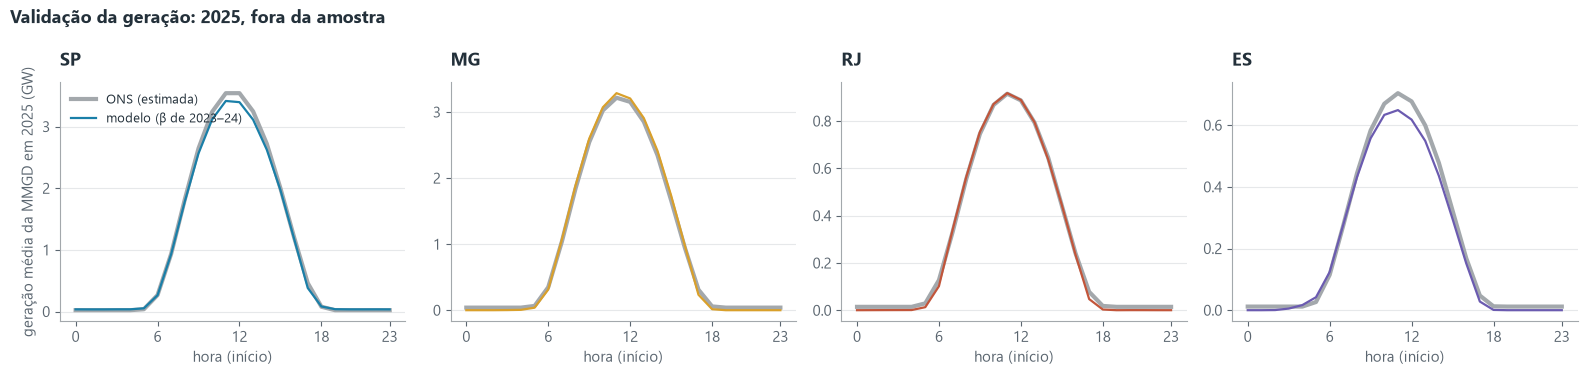

In [4]:
t = teste.assign(prev=gera(teste, ajusta_beta(treino, POR_HORA)).to_numpy())
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=False)
for ax, uf in zip(axes, UFS):
    g = t[t.uf == uf].groupby("h")[["mmgd", "prev"]].mean() / 1e3
    ax.plot(g.index, g.mmgd, color=estilo.NEUTRO, lw=3, label="ONS (estimada)")
    ax.plot(g.index, g.prev, color=CORES_UF[uf], lw=1.6, label="modelo (β de 2023–24)")
    ax.set_title(uf)
    ax.set_xticks([0, 6, 12, 18, 23])
    ax.set_xlabel("hora (início)")
axes[0].set_ylabel("geração média da MMGD em 2025 (GW)")
axes[0].legend(fontsize=9, loc="upper left")
fig.suptitle("Validação da geração: 2025, fora da amostra", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(RES / "rede_validacao_geracao.png")

**Leitura.**
- **O método reproduz a geração estimada pelo ONS fora da amostra.** Em 2025, com $\beta$ estimado só em 2023–24, o R² fica entre
  0,93 e 0,97 e o erro horário entre 11% (MG) e 20% (ES) da geração média. O viés ao meio-dia vai de −9% (ES) a +2% (MG); em SP,
  que pesa mais, é de −4%. O modelo tende a gerar um pouco menos que o ONS, então os números de 2030 são conservadores.
- **O $\beta$ por hora ganha por pouco** (erro até 0,3 ponto percentual menor; em ES fica igual) e fica: ele corrige a curva no fim da tarde,
  quando a radiação horizontal subestima o que chega aos painéis inclinados. Nas horas com pouca radiação média (antes das 7h e
  depois das 16h) a razão fica instável e o modelo usa o $\beta$ da UF.
- **$\beta$ entre 0,82 e 0,95** é a faixa de *performance ratio* de sistemas fotovoltaicos reais (perdas de inversor,
  temperatura, sujeira).
- **Cuidado com a validação:** a geração da MMGD do ONS não é medida, é estimada a partir de irradiância. Em ES o $\beta$ é o
  mesmo em todas as horas (0,95), sinal de que a estimativa do ONS ali é praticamente proporcional à radiação. A validação mostra
  que o modelo reproduz o ONS, e não a geração real.

## 2. Carga global até 2030

A carga global do ONS inclui o que a MMGD gera e é consumido atrás do medidor, então ela mede o consumo, e não o que a rede
entrega. O modelo projeta a **carga média mensal** (MW médios) de cada área, em log, e o perfil horário vem depois (seção 3).

A série começa em jan/2021 para deixar de fora a queda da pandemia em 2020, que nenhum dos candidatos sabe tratar sem uma
variável de intervenção. Candidatos (todos em log):

| modelo | o que supõe |
|---|---|
| sazonal ingênuo | o mesmo mês do ano anterior se repete |
| sazonal ingênuo com drift | ... mais o crescimento médio anual |
| ETS(A,N,A) | nível que se atualiza e sazonalidade, sem tendência |
| ETS(A,A,A) | nível, tendência e sazonalidade |
| ETS(A,Ad,A) | nível, tendência amortecida e sazonalidade |
| SARIMA(0,1,1)(0,1,1)₁₂ | o "modelo das companhias aéreas" (FPP3 §9.9) |

Validação cruzada com origem móvel (§5.10): previsões de **24 meses**, o maior horizonte que a série permite testar com pelo menos
dois anos de treino, a partir de cada mês de dez/2022 em diante, comparadas pelo RMSE e pelo CRPS no log (§5.9, com a
distribuição normal prevista). A projeção vai até 2030 (~50 meses), então o horizonte da validação precisa ser o mais longo
possível: com 12 meses, as origens caem quase todas no platô de 2025–26 e favorecem os modelos sem tendência.

In [5]:
cont = carga.notna().groupby(carga.index.to_period("M")).sum()
horas_mes = pd.Series(cont.index.days_in_month * 24, index=cont.index)
completo = cont.ge(0.95 * horas_mes, axis=0).all(axis=1)
mensal = carga.groupby(carga.index.to_period("M")).mean()[completo]
mensal.index = mensal.index.to_timestamp()
ylog = {a: np.log(mensal[a]["2021-01":]).asfreq("MS") for a in AREAS}
FIM_C = ylog["SUDESTE"].index[-1]
print(f"carga mensal: jan/2021 a {FIM_C:%m/%Y} ({len(ylog['SUDESTE'])} meses)")
MODELOS = ["sazonal ingênuo", "sazonal ingênuo com drift", "ETS(A,N,A)", "ETS(A,A,A)", "ETS(A,Ad,A)", "SARIMA(0,1,1)(0,1,1)₁₂"]
SEM_TENDENCIA = ["sazonal ingênuo", "ETS(A,N,A)"]


def ajusta(nome, y):
    if nome == "ETS(A,N,A)":
        return ETSModel(y, error="add", trend=None, seasonal="add", seasonal_periods=12).fit(disp=False)
    if nome == "ETS(A,A,A)":
        return ETSModel(y, error="add", trend="add", seasonal="add", seasonal_periods=12).fit(disp=False)
    if nome == "ETS(A,Ad,A)":
        return ETSModel(y, error="add", trend="add", damped_trend=True, seasonal="add", seasonal_periods=12).fit(disp=False)
    if nome.startswith("SARIMA"):
        return SARIMAX(y, order=(0, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
    return None


def prever(nome, y, h):
    """Média e desvio-padrão da previsão no log, h passos à frente."""
    if nome.startswith("sazonal"):
        dif = (y - y.shift(12)).dropna()
        drift = dif.mean() if "drift" in nome else 0.0
        sigma = (dif - drift).std()
        k = np.arange(h) // 12 + 1
        media = y.iloc[-12:].to_numpy()[np.arange(h) % 12] + k * drift
        return media, sigma * np.sqrt(k)
    r = ajusta(nome, y)
    if nome.startswith("ETS"):
        f = r.get_prediction(start=len(y), end=len(y) + h - 1).summary_frame(alpha=0.2)
        return f["mean"].to_numpy(), (f["pi_upper"] - f["pi_lower"]).to_numpy() / (2 * norm.ppf(0.9))
    f = r.get_forecast(h).summary_frame(alpha=0.2)
    return f["mean"].to_numpy(), (f["mean_ci_upper"] - f["mean_ci_lower"]).to_numpy() / (2 * norm.ppf(0.9))


def crps_normal(x, mu, sd):
    z = (x - mu) / sd
    return sd * (z * (2 * norm.cdf(z) - 1) + 2 * norm.pdf(z) - 1 / np.sqrt(np.pi))


HCV = 24
origens = pd.date_range("2022-12-01", FIM_C - pd.DateOffset(months=HCV), freq="MS")
linhas = []
for a in AREAS:
    for o in origens:
        y_tr, y_te = ylog[a][:o], ylog[a][o + pd.DateOffset(months=1):][:HCV].to_numpy()
        for nome in MODELOS:
            mu, sd = prever(nome, y_tr, HCV)
            linhas.append({"area": a, "origem": o, "modelo": nome,
                           "RMSE log": np.sqrt(np.mean((y_te - mu) ** 2)),
                           "CRPS log": crps_normal(y_te, mu, sd).mean(),
                           "CRPS log, 1º ano": crps_normal(y_te[:12], mu[:12], sd[:12]).mean(),
                           "viés 1º ano %": 100 * (np.exp(mu[:12]).mean() / np.exp(y_te[:12]).mean() - 1),
                           "viés 2º ano %": 100 * (np.exp(mu[12:]).mean() / np.exp(y_te[12:]).mean() - 1),
                           "cobertura 80%": np.mean(np.abs(y_te - mu) <= norm.ppf(0.9) * sd)})
cv = pd.DataFrame(linhas)
print(f"{len(origens)} origens ({origens[0]:%m/%Y} a {origens[-1]:%m/%Y}), 24 meses cada")
tab_cv = cv.groupby("modelo")[["CRPS log", "RMSE log", "CRPS log, 1º ano", "viés 1º ano %", "viés 2º ano %", "cobertura 80%"]].mean().sort_values("CRPS log")
tab_cv

carga mensal: jan/2021 a 10/2026 (70 meses)


23 origens (12/2022 a 10/2024), 24 meses cada


,CRPS log,RMSE log,"CRPS log, 1º ano",viés 1º ano %,viés 2º ano %,cobertura 80%
modelo,,,,,,
"ETS(A,N,A)",0.052,0.074,0.046,-3.271,-3.327,0.601
sazonal ingênuo com drift,0.053,0.087,0.049,-2.439,0.063,0.598
sazonal ingênuo,0.053,0.085,0.053,-4.878,-4.967,0.603
"ETS(A,A,A)",0.055,0.081,0.046,-1.976,0.421,0.476
"ETS(A,Ad,A)",0.055,0.079,0.048,-2.650,-1.787,0.526
"SARIMA(0,1,1)(0,1,1)₁₂",0.057,0.091,0.048,-1.403,1.613,0.727


In [6]:
cv.pivot_table(index="modelo", columns="area", values="CRPS log").loc[tab_cv.index].round(4)

area,ES,MG,RJ,SP,SUDESTE
modelo,,,,,
"ETS(A,N,A)",0.086,0.037,0.049,0.044,0.043
sazonal ingênuo com drift,0.079,0.045,0.062,0.040,0.040
sazonal ingênuo,0.083,0.036,0.052,0.051,0.045
"ETS(A,A,A)",0.078,0.044,0.068,0.042,0.041
"ETS(A,Ad,A)",0.079,0.037,0.072,0.045,0.045
"SARIMA(0,1,1)(0,1,1)₁₂",0.089,0.053,0.062,0.040,0.040


In [7]:
ESCOLHA = tab_cv.index[0]
# geradores separados: rodar ou não o gráfico não muda a projeção nem o sorteio do clima
RNG_CARGA, RNG_GRAFICO, RNG_CLIMA = (np.random.default_rng(s) for s in (6, 7, 8))
MESES_30 = pd.date_range("2030-01-01", "2030-12-01", freq="MS")
h30 = (2030 - FIM_C.year) * 12 + 12 - FIM_C.month


def simula(nome, y, h, n, rng):
    """n caminhos do log da carga média mensal, h meses à frente (sem incerteza dos parâmetros)."""
    if nome.startswith("sazonal"):
        dif = (y - y.shift(12)).dropna()
        drift = dif.mean() if "drift" in nome else 0.0
        # passeio aleatório sazonal: cada mês herda o mês do ano anterior. O choque de cada ano tem uma parte comum aos 12 meses
        # (desvio-padrão das médias anuais de `dif`) e uma parte mensal, para que a média anual não perca a variância do ano.
        anual = (dif - drift).groupby(dif.index.year).mean()
        sd_a, sd_m = anual.std(), (dif - drift - anual.reindex(dif.index.year).to_numpy()).std()
        anos_fut = pd.date_range(y.index[-1] + pd.DateOffset(months=1), periods=h, freq="MS").year.to_numpy()
        e = rng.normal(0, sd_a, (anos_fut.max() - anos_fut.min() + 1, n))[anos_fut - anos_fut.min()] + rng.normal(0, sd_m, (h, n))
        caminhos = np.empty((h, n))
        for i in range(h):
            caminhos[i] = (caminhos[i - 12] if i >= 12 else y.iloc[-12 + i]) + drift + e[i]
        return caminhos
    r = ajusta(nome, y)
    return np.asarray(r.simulate(nsimulations=h, repetitions=n, anchor="end", rng=rng)).reshape(h, n)


# sensibilidade: o melhor modelo da outra família (com tendência, se o escolhido não tiver; sem tendência, se tiver)
outra = [m for m in tab_cv.index if (m in SEM_TENDENCIA) != (ESCOLHA in SEM_TENDENCIA)]
ESCOLHA_TEND = outra[0]
carga_30 = {}                                      # modelo -> área -> N x 12 meses de 2030, MW médios
for nome in dict.fromkeys([ESCOLHA, ESCOLHA_TEND]):
    carga_30[nome] = {a: np.exp(simula(nome, ylog[a], h30, N, RNG_CARGA))[-12:].T for a in AREAS}
carga_mensal_30 = carga_30[ESCOLHA]
historico_anual = mensal.groupby(mensal.index.year).mean()
print(f"modelo escolhido: {ESCOLHA}; sensibilidade: {ESCOLHA_TEND}")
pd.concat({nome: pd.DataFrame({a: {
    "2025 (observado, GW médios)": historico_anual.loc[2025, a] / 1e3,
    "2030 média": c[a].mean() / 1e3,
    "2030 P10": np.quantile(c[a].mean(axis=1), 0.1) / 1e3,
    "2030 P90": np.quantile(c[a].mean(axis=1), 0.9) / 1e3,
    "crescimento % ao ano": 100 * ((c[a].mean() / historico_anual.loc[2025, a]) ** (1 / 5) - 1)}
    for a in AREAS}).T for nome, c in carga_30.items()})

modelo escolhido: ETS(A,N,A); sensibilidade: sazonal ingênuo com drift


2025 (observado, GW médios)  2030 média  \
ETS(A,N,A)                SP                            19.058      18.916   
                          MG                             8.097       8.278   
                          RJ                             6.190       6.360   
                          ES                             1.933       2.158   
                          SUDESTE                       35.279      35.912   
sazonal ingênuo com drift SP                            19.058      21.248   
                          MG                             8.097       8.859   
                          RJ                             6.190       6.459   
                          ES                             1.933       2.414   
                          SUDESTE                       35.279      38.792   

                                   2030 P10  2030 P90  crescimento % ao ano  
ETS(A,N,A)                SP         16.407    21.460                -0.150  
                          MG          6.631    10.069                 0.441  
                          RJ          5.612     7.199                 0.542  
                          ES          1.679     2.678                 2.228  
                          SUDESTE    31.654    40.661                 0.356  
sazonal ingênuo com drift SP         19.642    22.864                 2.199  
                          MG          8.123     9.639                 1.813  
                          RJ          5.670     7.273                 0.854  
                          ES          2.104     2.716                 4.543  
                          SUDESTE    35.908    41.579                 1.917

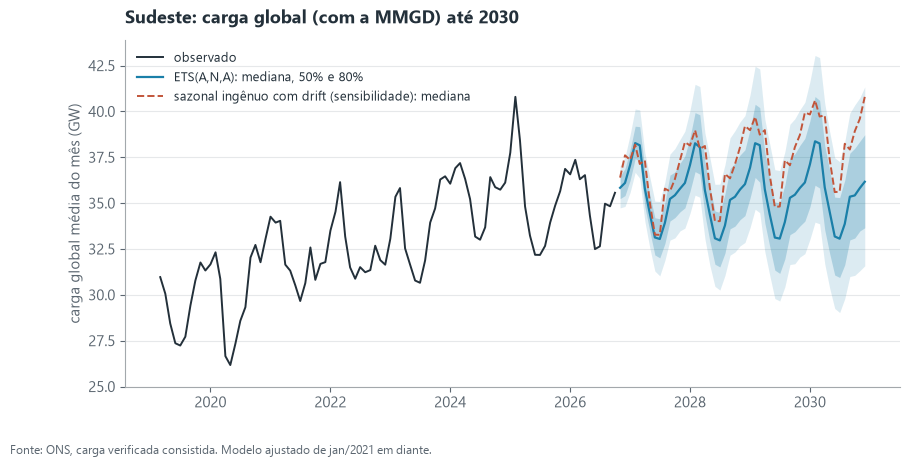

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.5))
hist = mensal["SUDESTE"] / 1e3
ax.plot(hist.index, hist, color=estilo.TINTA, lw=1.4, label="observado")
caminhos = np.exp(simula(ESCOLHA, ylog["SUDESTE"], h30, 2000, RNG_GRAFICO)) / 1e3
fut = pd.date_range(FIM_C + pd.DateOffset(months=1), periods=h30, freq="MS")
for q, al in [(0.1, 0.15), (0.25, 0.25)]:
    ax.fill_between(fut, np.quantile(caminhos, q, axis=1), np.quantile(caminhos, 1 - q, axis=1), color=CORES_UF["SP"], alpha=al, lw=0)
ax.plot(fut, np.median(caminhos, axis=1), color=CORES_UF["SP"], lw=1.6, label=f"{ESCOLHA}: mediana, 50% e 80%")
if ESCOLHA_TEND != ESCOLHA:
    tend = np.exp(simula(ESCOLHA_TEND, ylog["SUDESTE"], h30, 2000, RNG_GRAFICO)) / 1e3
    ax.plot(fut, np.median(tend, axis=1), color=CORES_UF["RJ"], lw=1.4, ls="--", label=f"{ESCOLHA_TEND} (sensibilidade): mediana")
ax.set_ylim(25, None)
ax.set_ylabel("carga global média do mês (GW)")
ax.legend(loc="upper left", fontsize=9.5)
ax.set_title("Sudeste: carga global (com a MMGD) até 2030")
estilo.fonte_rodape(fig, "Fonte: ONS, carga verificada consistida. Modelo ajustado de jan/2021 em diante.")
fig.savefig(RES / "rede_carga_global_2030.png")

**Leitura.**
- **A validação cruzada não separa bem os modelos.** O ETS(A,N,A), sem tendência, tem o menor CRPS em 24 meses (0,052), mas os
  ingênuos sazonais e o ETS(A,A,A) ficam a 0,001–0,003 dele. A diferença está no viés: o ETS(A,N,A) fica 3,3% abaixo do realizado
  nos dois anos, enquanto o sazonal ingênuo com drift tem viés zero no 2º ano. A carga do Sudeste cresceu ~3,6% ao ano entre 2021 e
  2024 e parou em 2025–26 (−0,6% e −0,2%); os modelos sem tendência ganham porque as origens recentes caem no platô.
- A cobertura do intervalo de 80% fica em ~60% em 24 meses para todos os modelos: os intervalos da carga são estreitos demais
  nesse horizonte.
- **Por isso a carga entra em dois cenários de mesmo peso:** estável (ETS(A,N,A), o escolhido: 35,9 GW médios em 2030, +0,4% ao ano,
  80%: 31,7 a 40,7 GW) e crescendo (sazonal ingênuo com drift, a sensibilidade: 38,8 GW, +1,9% ao ano, 80%: 36,1 a 41,6 GW). O drift
  tem um choque anual comum aos 12 meses, para que o leque da média anual não fique estreito.

## 3. O ano de 2030 hora a hora

Cada caminho recebe um **ano de clima** sorteado entre 2021 e 2025. Desse ano vêm, juntos, a radiação horária de cada UF e o
**perfil horário da carga** (a carga de cada hora dividida pela média do seu mês). Usar o mesmo ano para os dois preserva a
relação entre sol, calor e consumo. Cada dia de 2030 é casado com o dia do ano de clima mais próximo que cai no mesmo dia da
semana (deslocamento de até 3 dias), para que fins de semana caiam em fins de semana.

Em cada caminho e hora de 2030:
- carga global = carga média do mês (seção 2) × perfil horário do ano de clima;
- geração = potência instalada no meio do mês (fase 5) × $\beta_{UF,h}$ × radiação do ano de clima, somada nas quatro UFs;
- carga líquida = carga global − geração.

São 1.000 caminhos por cenário (dos 4.000 da fase 5).

In [9]:
DIAS_30 = pd.date_range("2030-01-01", "2030-12-31", freq="D")
MES_DO_DIA = DIAS_30.month.to_numpy() - 1
carga_h = carga.interpolate(limit=6)
rad_h = rad.interpolate(limit=3)
cheio = pd.date_range("2020-12-01", "2026-01-31 23:00", freq="h")
carga_h, rad_h = carga_h.reindex(cheio), rad_h.reindex(cheio)
# lacunas maiores: média da mesma hora no mesmo mês e ano
for df in (carga_h, rad_h):
    chave = [df.index.year, df.index.month, df.index.hour]
    df.fillna(df.groupby(chave).transform("mean"), inplace=True)
media_mes = carga_h.groupby([carga_h.index.year, carga_h.index.month]).transform("mean")
perfil = carga_h / media_mes
print("lacunas restantes:", int(perfil.isna().sum().sum()), int(rad_h.isna().sum().sum()))


def dias_fonte(ano):
    """Dia do ano de clima casado com cada dia de 2030 (mesmo dia da semana, até 3 dias de deslocamento)."""
    base = pd.to_datetime({"year": ano, "month": DIAS_30.month, "day": DIAS_30.day})
    desloc = (DIAS_30.weekday.to_numpy() - base.dt.weekday.to_numpy()) % 7
    desloc = np.where(desloc > 3, desloc - 7, desloc)
    return base + pd.to_timedelta(desloc, unit="D")


def matriz(df, col, ano):
    """365 x 24 do ano de clima, na ordem dos dias de 2030."""
    horas = (dias_fonte(ano).to_numpy()[:, None] + np.arange(24) * np.timedelta64(1, "h")).ravel()
    return df[col].reindex(horas).to_numpy().reshape(365, 24)


def renormaliza(m):
    """Depois do casamento dos dias, a média do perfil em cada mês de 2030 volta a ser 1 (a carga média do mês é a projetada)."""
    medias = pd.Series(m.mean(axis=1)).groupby(MES_DO_DIA).transform("mean").to_numpy()
    return m / medias[:, None]


PERFIL = {a: {ano: renormaliza(matriz(perfil, a, ano)) for ano in ANOS_CLIMA} for a in AREAS}
RAD = {uf: {ano: matriz(rad_h, uf, ano) for ano in ANOS_CLIMA} for uf in UFS}
# clima "médio" (para a decomposição da incerteza): média dos anos de clima, dia a dia
PERFIL_MEDIO = {a: np.mean(list(PERFIL[a].values()), axis=0) for a in AREAS}
RAD_MEDIA = {uf: np.mean(list(RAD[uf].values()), axis=0) for uf in UFS}
BETA_H = {uf: beta_tab[uf].reindex(range(24)).fillna(0.0).to_numpy() for uf in UFS}
ano_clima = RNG_CLIMA.choice(ANOS_CLIMA, N)

# potência instalada no meio de cada mês de 2030, por cenário e UF: N x 12
mw_meio = {}
for nome in TODOS:
    for uf in UFS:
        p = (cen[(cen.cenario == nome) & (cen.uf == uf) & (cen.caminho < N) & (cen.mes >= "2029-12-01")]
             .pivot(index="caminho", columns="mes", values="mw_instalado").to_numpy())
        mw_meio[(nome, uf)] = (p[:, :-1] + p[:, 1:]) / 2


def simula_2030(nome, area="SUDESTE", modelo_carga=None, fixa_carga=False, fixa_mw=False, fixa_clima=False):
    """Carga global, geração e carga líquida por hora: arrays N x 365 x 24 (MW).
    fixa_carga / fixa_mw trocam os caminhos pela média entre caminhos; fixa_clima usa o perfil e a radiação médios dos anos
    de clima em todos os caminhos. Servem para decompor a incerteza."""
    ufs = UFS if area == "SUDESTE" else [area]
    cm = carga_30[modelo_carga or ESCOLHA][area]
    if fixa_carga:
        cm = np.broadcast_to(cm.mean(axis=0), cm.shape)
    glob = np.empty((N, 365, 24), dtype=np.float32)
    ger = np.zeros((N, 365, 24), dtype=np.float32)
    for ano in ANOS_CLIMA:
        p = np.flatnonzero(ano_clima == ano)
        perf = PERFIL_MEDIO[area] if fixa_clima else PERFIL[area][ano]
        glob[p] = cm[p][:, MES_DO_DIA, None] * perf[None]
        for uf in ufs:
            mw = mw_meio[(nome, uf)]
            if fixa_mw:
                mw = np.broadcast_to(mw.mean(axis=0), mw.shape)
            r = RAD_MEDIA[uf] if fixa_clima else RAD[uf][ano]
            ger[p] += mw[p][:, MES_DO_DIA, None] * (BETA_H[uf] * r)[None]
    return glob, ger, glob - ger


sim = {nome: simula_2030(nome) for nome in CENARIOS}
print("ok:", {k: v[2].shape for k, v in sim.items()})

lacunas restantes: 0 0


ok: {'base (sem choque)': (1000, 365, 24), '0,5× o choque de 2023': (1000, 365, 24), '1× o choque de 2023': (1000, 365, 24), '2× o choque de 2023': (1000, 365, 24)}


## 4. Indicadores

Os mesmos indicadores são calculados nos dados observados do ONS (2021 a 2025; carga líquida = carga global − MMGD estimada
pelo ONS) e nos caminhos de 2030:

- **carga líquida ao meio-dia:** média da hora 12h–13h;
- **parcela da MMGD ao meio-dia:** geração / carga global nessa hora;
- **rampa de 3 horas:** a maior subida da carga líquida em 3 horas, começando entre 15h e 20h, a medida usada pelo operador da
  Califórnia (CAISO) para a "curva do pato". É a potência que as outras usinas precisam acrescentar, rápido, quando o sol se põe;
- **subida vale–pico:** pico da carga líquida entre 17h e 22h menos o mínimo entre 9h e 16h, no mesmo dia (a amplitude total que
  as outras usinas cobrem ao longo da tarde);
- **profundidade do vale:** menor carga líquida da madrugada (0h–6h) menos a menor entre 9h e 16h, em GW. Positiva quando o
  meio-dia já é o vale da rede;
- **dias com vale ao meio-dia:** fração dos dias com profundidade positiva. É a versão de contagem da mesma medida, que satura
  perto de 100%;
- **mínimo da carga líquida:** a menor hora do ano.

In [10]:
def indicadores(glob, ger, liq):
    """Recebe arrays (..., dias, 24); devolve médias por dia e indicadores diários."""
    dia_min = liq[..., 9:17].min(axis=-1)
    profundidade = liq[..., 0:7].min(axis=-1) - dia_min
    return {
        "carga líquida ao meio-dia (GW)": liq[..., MEIO_DIA] / 1e3,
        "MMGD / carga global ao meio-dia (%)": 100 * ger[..., MEIO_DIA] / glob[..., MEIO_DIA],
        "rampa de 3 h (GW)": (liq[..., 18:24] - liq[..., 15:21]).max(axis=-1) / 1e3,
        "subida vale–pico (GW)": (liq[..., 17:23].max(axis=-1) - dia_min) / 1e3,
        "profundidade do vale (GW)": profundidade / 1e3,
        "dias com vale ao meio-dia (%)": 100 * (profundidade > 0),
        "mínimo da carga líquida (GW)": liq.min(axis=-1) / 1e3,
    }


# observado
obs = pd.DataFrame({"glob": carga["SUDESTE"], "ger": mmgd_ons["SUDESTE"]}).dropna()
obs = obs[obs.index.year.isin(range(2019, 2026))]
obs["liq"] = obs.glob - obs.ger
dias_obs = obs.index.normalize()
cubo = {c: obs[c].groupby([dias_obs, obs.index.hour]).mean().unstack() for c in ["glob", "ger", "liq"]}
ok = cubo["glob"].notna().all(axis=1)
ind_obs = indicadores(*(cubo[c][ok].to_numpy() for c in ["glob", "ger", "liq"]))
anos_obs = cubo["glob"][ok].index.year
tab_obs = pd.DataFrame({k: pd.Series(v).groupby(anos_obs).mean() for k, v in ind_obs.items()})
tab_obs["mínimo da carga líquida (GW)"] = pd.Series(ind_obs["mínimo da carga líquida (GW)"]).groupby(anos_obs).min()

# 2030
ind_30 = {nome: indicadores(*sim[nome]) for nome in CENARIOS}


def resumo_2030(nome):
    out = {}
    for k, v in ind_30[nome].items():
        por_caminho = v.min(axis=1) if k.startswith("mínimo") else v.mean(axis=1)
        out[k] = por_caminho.mean()
        out[k + " P10"] = np.quantile(por_caminho, 0.1)
        out[k + " P90"] = np.quantile(por_caminho, 0.9)
    return out


tab_30 = pd.DataFrame({f"2030 {nome}": resumo_2030(nome) for nome in CENARIOS}).T
principais = [c for c in tab_30.columns if not c.endswith(("P10", "P90"))]
pd.concat([tab_obs.rename(index=str), tab_30[principais]]).round(2)

,carga líquida ao meio-dia (GW),MMGD / carga global ao meio-dia (%),rampa de 3 h (GW),subida vale–pico (GW),profundidade do vale (GW),dias com vale ao meio-dia (%),mínimo da carga líquida (GW)
2019,31.29,0.96,2.83,3.71,-6.75,0.00,18.06
2020,31.32,2.38,3.41,4.89,-5.83,0.00,18.23
2021,32.37,4.27,3.38,5.12,-5.45,0.00,21.33
2022,31.95,7.35,3.81,6.06,-4.83,0.00,21.11
2023,31.17,12.96,4.20,7.41,-3.27,12.88,20.73
2024,31.38,16.66,5.02,9.08,-1.84,25.96,21.62
2025,29.27,22.10,6.53,11.48,-0.35,36.16,17.94
2030 base (sem choque),23.50,38.92,9.31,17.89,5.79,95.98,10.31
"2030 0,5× o choque de 2023",24.03,37.50,9.04,17.35,5.28,95.13,11.27
2030 1× o choque de 2023,24.40,36.51,8.85,16.97,4.93,94.36,11.89


In [11]:
tab_30.round(2)

,carga líquida ao meio-dia (GW),carga líquida ao meio-dia (GW) P10,carga líquida ao meio-dia (GW) P90,MMGD / carga global ao meio-dia (%),MMGD / carga global ao meio-dia (%) P10,MMGD / carga global ao meio-dia (%) P90,rampa de 3 h (GW),rampa de 3 h (GW) P10,rampa de 3 h (GW) P90,subida vale–pico (GW),...,subida vale–pico (GW) P90,profundidade do vale (GW),profundidade do vale (GW) P10,profundidade do vale (GW) P90,dias com vale ao meio-dia (%),dias com vale ao meio-dia (%) P10,dias com vale ao meio-dia (%) P90,mínimo da carga líquida (GW),mínimo da carga líquida (GW) P10,mínimo da carga líquida (GW) P90
2030 base (sem choque),23.50,18.57,28.87,38.92,32.30,46.28,9.31,8.25,10.52,17.89,...,20.11,5.79,3.80,8.03,95.98,91.23,99.18,10.31,5.11,15.48
"2030 0,5× o choque de 2023",24.03,19.14,29.29,37.50,31.41,44.07,9.04,8.10,10.09,17.35,...,19.32,5.28,3.49,7.21,95.13,89.32,98.90,11.27,6.43,16.05
2030 1× o choque de 2023,24.40,19.64,29.60,36.51,30.79,42.63,8.85,7.99,9.80,16.97,...,18.74,4.93,3.26,6.67,94.36,87.40,98.63,11.89,7.19,16.53
2030 2× o choque de 2023,24.85,20.22,29.97,35.31,30.03,40.85,8.62,7.84,9.48,16.52,...,18.03,4.50,2.97,6.08,93.22,85.75,98.08,12.59,8.17,17.02


**Leitura.**
- **Em 2030, a MMGD cobre cerca de 39% da carga do Sudeste ao meio-dia no cenário base** (80%: 32% a 46%), contra 22% em 2025 e 1% em
  2019. A carga líquida às 12h–13h cai de 29,3 GW (2025) para 23,5 GW (80%: 18,6 a 28,9 GW).
- **O meio-dia vira o vale da rede.** A profundidade do vale passa de −0,35 GW em 2025 (o meio-dia ainda ficava, em média, um pouco
  acima da madrugada) para +5,8 GW em 2030 (80%: 3,8 a 7,9 GW). Em contagem: o vale cai ao meio-dia em 36% dos dias de 2025 e em
  96% dos de 2030.
- **A rampa de 3 horas no fim da tarde sobe de 6,5 GW para 9,3 GW (+43%; 80%: 8,3 a 10,5 GW)**, e a subida total do vale ao pico, de
  11,5 para 17,9 GW. O mínimo da carga líquida no ano cai de 17,9 GW para ~10 GW.
- **A regra de 2029 muda pouco o quadro**, mesmo no teto: no choque 2× a parcela ao meio-dia fica em 35%, a rampa em 8,6 GW e a
  profundidade do vale em 4,5 GW. Os ~22 GW instalados até 2028 já bastam para inverter a curva.

## 5. O que mais pesa: regra de 2029, carga, modelo da potência e incerteza interna

Os indicadores de 2030 dependem de quatro fontes de incerteza, que a tabela e o gráfico abaixo comparam na mesma escala:

1. **a regra de 2029:** da base ao choque 2× (que é um teto, fase 5);
2. **a carga:** o modelo escolhido contra o melhor da outra família (com ou sem tendência);
3. **o modelo da potência instalada:** a base projetada pelos outros modelos plausíveis da fase 5 (Bass, combinação tendência
   quebrada + Bass, tendência quebrada, ETS), além do ETS + Bass escolhido. A fase 5 mostrou que essa é a maior incerteza sobre
   os GW de 2030;
4. **a incerteza dentro do modelo:** o intervalo de 80% dos caminhos da base, decomposto em nível da carga, potência
   instalada e clima (congelando as outras duas: carga e potência na média dos caminhos, clima na média dos anos).

In [12]:
def resumo_medio(ind):
    return {k: (v.min(axis=1) if k.startswith("mínimo") else v.mean(axis=1)) for k, v in ind.items()}


# carga com o modelo da outra família, em todos os cenários
sens_carga = {}
for nome in CENARIOS:
    g, e, l = simula_2030(nome, modelo_carga=ESCOLHA_TEND)
    sens_carga[f"2030 {nome}"] = {k: v.mean() for k, v in resumo_medio(indicadores(g, e, l)).items()}
    del g, e, l

# base projetada por outros modelos da potência instalada (carga do modelo escolhido)
por_modelo = {"comb. ETS + Bass (escolhido)": {k: v.mean() for k, v in resumo_medio(ind_30[CENARIOS[0]]).items()}}
mw_dez = {"comb. ETS + Bass (escolhido)": sum(mw_meio[(CENARIOS[0], uf)][:, -1] for uf in UFS).mean() / 1e3}
for nome in ALTERNATIVOS:
    g, e, l = simula_2030(nome)
    por_modelo[nome.removeprefix("base, ")] = {k: v.mean() for k, v in resumo_medio(indicadores(g, e, l)).items()}
    mw_dez[nome.removeprefix("base, ")] = sum(mw_meio[(nome, uf)][:, -1] for uf in UFS).mean() / 1e3
    del g, e, l
tab_modelo = pd.DataFrame(por_modelo).T.assign(**{"GW instalados (dez/2030, meio do mês)": pd.Series(mw_dez)})
tab_modelo = tab_modelo.sort_values("GW instalados (dez/2030, meio do mês)")

# decomposição da incerteza interna (base): largura P10–P90 entre caminhos
largura = {}
for rot, kw in [("tudo", {}),
                ("só o nível da carga varia", {"fixa_mw": True, "fixa_clima": True}),
                ("só a potência instalada varia", {"fixa_carga": True, "fixa_clima": True}),
                ("só o clima varia (ano sorteado)", {"fixa_carga": True, "fixa_mw": True})]:
    g, e, l = simula_2030(CENARIOS[0], **kw)
    largura[rot] = {k: np.subtract(*np.quantile(v, [0.9, 0.1])) for k, v in resumo_medio(indicadores(g, e, l)).items()}
    del g, e, l

print(f"Carga com {ESCOLHA_TEND} (sensibilidade):")
display(pd.concat({ESCOLHA: tab_30[principais], ESCOLHA_TEND: pd.DataFrame(sens_carga).T}).round(2))
print("Base (sem choque) com outros modelos da potência instalada:")
display(tab_modelo.round(2))
print("Largura do intervalo de 80% na base (P90 − P10), por fonte:")
display(pd.DataFrame(largura).T.round(2))

Carga com sazonal ingênuo com drift (sensibilidade):


carga líquida ao meio-dia (GW)  \
ETS(A,N,A)                2030 base (sem choque)                               23.50   
                          2030 0,5× o choque de 2023                           24.03   
                          2030 1× o choque de 2023                             24.40   
                          2030 2× o choque de 2023                             24.85   
sazonal ingênuo com drift 2030 base (sem choque)                               26.57   
                          2030 0,5× o choque de 2023                           27.10   
                          2030 1× o choque de 2023                             27.47   
                          2030 2× o choque de 2023                             27.92   

                                                      MMGD / carga global ao meio-dia (%)  \
ETS(A,N,A)                2030 base (sem choque)                                    38.92   
                          2030 0,5× o choque de 2023                                37.50   
                          2030 1× o choque de 2023                                  36.51   
                          2030 2× o choque de 2023                                  35.31   
sazonal ingênuo com drift 2030 base (sem choque)                                    36.05   
                          2030 0,5× o choque de 2023                                34.75   
                          2030 1× o choque de 2023                                  33.83   
                          2030 2× o choque de 2023                                  32.72   

                                                      rampa de 3 h (GW)  \
ETS(A,N,A)                2030 base (sem choque)                   9.31   
                          2030 0,5× o choque de 2023               9.04   
                          2030 1× o choque de 2023                 8.85   
                          2030 2× o choque de 2023                 8.62   
sazonal ingênuo com drift 2030 base (sem choque)                   9.47   
                          2030 0,5× o choque de 2023               9.20   
                          2030 1× o choque de 2023                 9.01   
                          2030 2× o choque de 2023                 8.79   

                                                      subida vale–pico (GW)  \
ETS(A,N,A)                2030 base (sem choque)                      17.89   
                          2030 0,5× o choque de 2023                  17.35   
                          2030 1× o choque de 2023                    16.97   
                          2030 2× o choque de 2023                    16.52   
sazonal ingênuo com drift 2030 base (sem choque)                      18.14   
                          2030 0,5× o choque de 2023                  17.61   
                          2030 1× o choque de 2023                    17.24   
                          2030 2× o choque de 2023                    16.78   

                                                      profundidade do vale (GW)  \
ETS(A,N,A)                2030 base (sem choque)                           5.79   
                          2030 0,5× o choque de 2023                       5.28   
                          2030 1× o choque de 2023                         4.93   
                          2030 2× o choque de 2023                         4.50   
sazonal ingênuo com drift 2030 base (sem choque)                           5.13   
                          2030 0,5× o choque de 2023                       4.62   
                          2030 1× o choque de 2023                         4.27   
                          2030 2× o choque de 2023                         3.84   

                                                      dias com vale ao meio-dia (%)  \
ETS(A,N,A)                2030 base (sem choque)                              95.98   
                          2030 0,5× o choque de 2023                          95.13   
                          

Base (sem choque) com outros modelos da potência instalada:


,carga líquida ao meio-dia (GW),MMGD / carga global ao meio-dia (%),rampa de 3 h (GW),subida vale–pico (GW),profundidade do vale (GW),dias com vale ao meio-dia (%),mínimo da carga líquida (GW),"GW instalados (dez/2030, meio do mês)"
Bass,27.32,28.74,7.39,14.04,2.13,78.79,15.68,18.65
comb. quebrada + Bass,24.71,35.68,8.67,16.67,4.62,93.94,12.15,23.83
comb. ETS + Bass (escolhido),23.50,38.92,9.31,17.89,5.79,95.98,10.31,26.39
tendência quebrada (d=0),22.10,42.61,9.99,19.31,7.11,97.79,8.34,29.01
"ETS(A,Ad,N)",19.67,49.09,11.29,21.75,9.43,98.84,4.56,34.13


Largura do intervalo de 80% na base (P90 − P10), por fonte:


,carga líquida ao meio-dia (GW),MMGD / carga global ao meio-dia (%),rampa de 3 h (GW),subida vale–pico (GW),profundidade do vale (GW),dias com vale ao meio-dia (%),mínimo da carga líquida (GW)
tudo,10.31,13.99,2.26,4.12,4.23,7.95,10.38
só o nível da carga varia,9.55,9.66,0.46,0.77,2.06,0.82,8.28
só a potência instalada varia,3.91,10.31,2.01,3.94,3.72,0.55,5.62
só o clima varia (ano sorteado),0.41,1.31,1.00,1.27,0.34,1.10,3.82


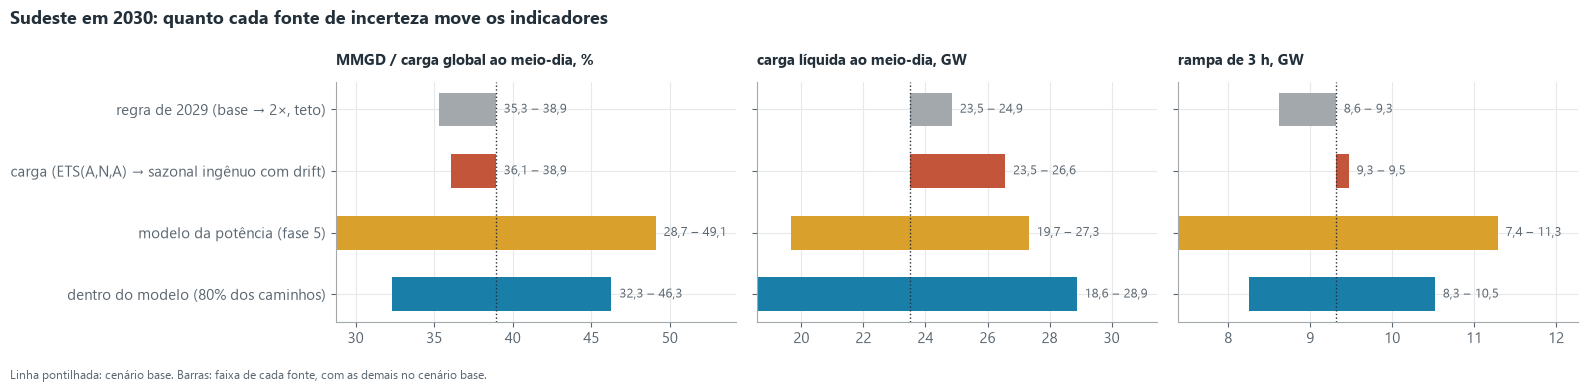

In [13]:
IND_T = ["MMGD / carga global ao meio-dia (%)", "carga líquida ao meio-dia (GW)", "rampa de 3 h (GW)"]
base_v = tab_30.loc[f"2030 {CENARIOS[0]}"]
faixas = {}
for k in IND_T:
    faixas[k] = {
        "regra de 2029 (base → 2×, teto)": sorted([base_v[k], tab_30.loc[f"2030 {CENARIOS[-1]}", k]]),
        f"carga ({ESCOLHA} → {ESCOLHA_TEND})": sorted([base_v[k], sens_carga[f"2030 {CENARIOS[0]}"][k]]),
        "modelo da potência (fase 5)": [tab_modelo[k].min(), tab_modelo[k].max()],
        "dentro do modelo (80% dos caminhos)": [base_v[k + " P10"], base_v[k + " P90"]],
    }
fig, axes = plt.subplots(1, 3, figsize=(16, 3.6), sharey=True)
for ax, k in zip(axes, IND_T):
    fonte = list(faixas[k])
    for j, f in enumerate(fonte):
        lo, hi = faixas[k][f]
        ax.barh(j, hi - lo, left=lo, color=[estilo.NEUTRO, CORES_UF["RJ"], CORES_UF["MG"], CORES_UF["SP"]][j], height=0.55)
        ax.text(hi, j, f"  {lo:.1f} – {hi:.1f}".replace(".", ","), va="center", fontsize=9, color=estilo.TINTA_SUAVE)
    ax.axvline(base_v[k], color=estilo.TINTA, lw=1, ls=":")
    ax.set_yticks(range(len(fonte)))
    ax.set_yticklabels(fonte)
    ax.set_title(k.replace(" (%)", ", %").replace(" (GW)", ", GW"), fontsize=11)
    ax.grid(axis="x")
    ax.margins(x=0.25)
axes[0].invert_yaxis()
fig.suptitle("Sudeste em 2030: quanto cada fonte de incerteza move os indicadores", x=0.01, ha="left", fontsize=13, fontweight="bold")
estilo.fonte_rodape(fig, "Linha pontilhada: cenário base. Barras: faixa de cada fonte, com as demais no cenário base.")
fig.tight_layout()
fig.savefig(RES / "rede_fontes_incerteza.png")

**Leitura.**
- **O modelo da potência instalada é a maior fonte de incerteza da parcela e da rampa.** Com a mesma carga, a parcela ao meio-dia vai
  de 29% (Bass, 18,7 GW em dez/2030) a 49% (ETS, 34,1 GW), e a rampa de 3 horas de 7,4 a 11,3 GW. Mesmo no Bass, o mais pessimista,
  o vale cai ao meio-dia em 79% dos dias: a curva do pato aparece em todos os modelos.
- **A carga domina a carga líquida em GW.** No intervalo interno da base (10,3 GW de largura na carga líquida ao meio-dia), o nível
  da carga sozinho responde por 9,6 GW, a potência instalada por 3,9 GW e o clima por 0,4 GW. Na parcela, carga e potência pesam
  parecido (9,7 e 10,3 pontos) e o clima pouco (1,3). Na rampa de 3 horas, a potência domina (2,0 GW), seguida do clima (1,0 GW);
  a carga quase não pesa (0,5 GW), porque sobe o pico da noite e o meio-dia juntos. O clima pesa mais nos extremos que nas médias:
  no mínimo anual da carga líquida, ele responde por 3,8 GW de largura.
- **A regra de 2029 é a menor das quatro fontes**: move a parcela 3,6 pontos (do teto 2× à base), menos que a carga (2,9 pontos com
  crescimento de 1,9% ao ano), muito menos que o modelo da potência (20 pontos) e que o intervalo interno (14 pontos).

## 6. O dia típico e o ano de 2030

O gráfico da esquerda é o dia médio de outubro (mês de sol forte e carga ainda moderada) em 2025, observado, e em 2030 nos
cenários. O da direita mostra a carga líquida ao meio-dia mês a mês em 2030.

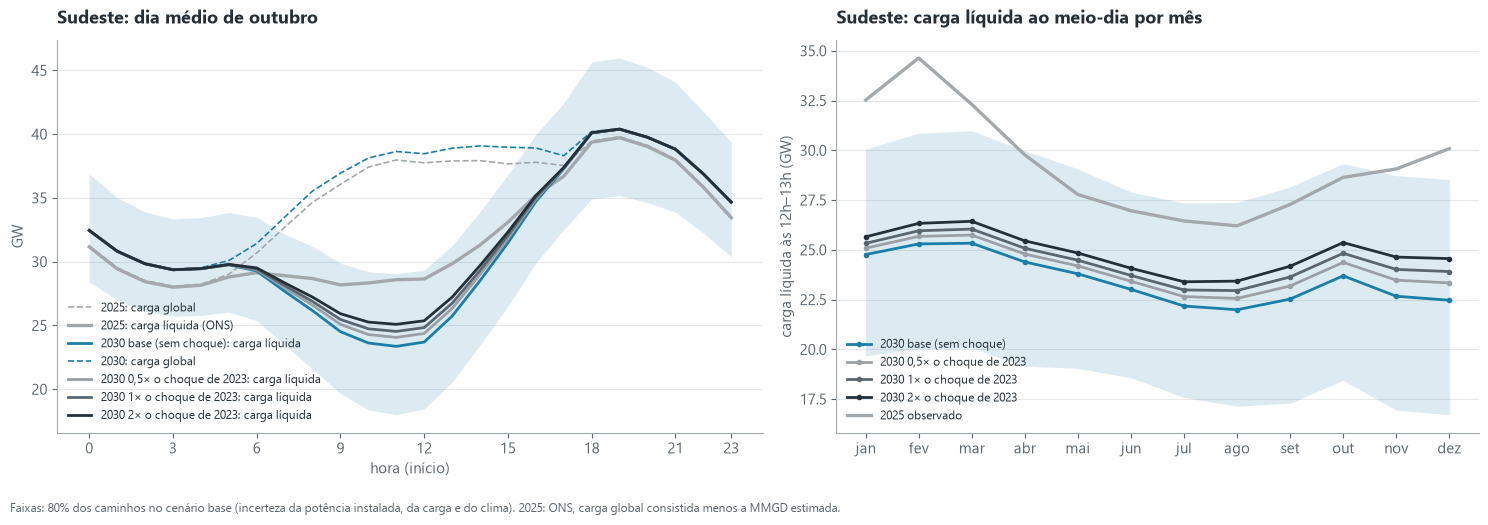

In [14]:
MES_DIA = 10
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.1, 1]})
mask_obs = (cubo["liq"].index.year == 2025) & (cubo["liq"].index.month == MES_DIA)
ax1.plot(range(24), cubo["glob"][mask_obs].mean() / 1e3, color=estilo.NEUTRO, lw=1.2, ls="--", label="2025: carga global")
ax1.plot(range(24), cubo["liq"][mask_obs].mean() / 1e3, color=estilo.NEUTRO, lw=2.4, label="2025: carga líquida (ONS)")
CORES_CEN = dict(zip(CENARIOS, [CORES_UF["SP"], "#9AA0A6", "#5B6670", estilo.TINTA]))
dias_mes = MES_DO_DIA == MES_DIA - 1
for nome in CENARIOS:
    glob, ger, liq = sim[nome]
    curva = liq[:, dias_mes].mean(axis=1) / 1e3
    ax1.plot(range(24), curva.mean(axis=0), color=CORES_CEN[nome], lw=2, label=f"2030 {nome}: carga líquida")
    if nome == CENARIOS[0]:
        ax1.fill_between(range(24), np.quantile(curva, 0.1, axis=0), np.quantile(curva, 0.9, axis=0), color=CORES_CEN[nome], alpha=0.15, lw=0)
        ax1.plot(range(24), (glob[:, dias_mes].mean(axis=1) / 1e3).mean(axis=0), color=CORES_CEN[nome], lw=1.2, ls="--", label="2030: carga global")
ax1.set_xticks([0, 3, 6, 9, 12, 15, 18, 21, 23])
ax1.set_xlabel("hora (início)")
ax1.set_ylabel("GW")
ax1.set_title(f"Sudeste: dia médio de outubro")
ax1.legend(fontsize=8.5, loc="lower left")

meses = np.arange(1, 13)
for nome in CENARIOS:
    v = ind_30[nome]["carga líquida ao meio-dia (GW)"]
    por_mes = np.stack([v[:, MES_DO_DIA == m - 1].mean(axis=1) for m in meses], axis=1)
    ax2.plot(meses, por_mes.mean(axis=0), color=CORES_CEN[nome], lw=2, marker="o", ms=3, label=f"2030 {nome}")
    if nome == CENARIOS[0]:
        ax2.fill_between(meses, np.quantile(por_mes, 0.1, axis=0), np.quantile(por_mes, 0.9, axis=0), color=CORES_CEN[nome], alpha=0.15, lw=0)
o25 = pd.Series(ind_obs["carga líquida ao meio-dia (GW)"], index=cubo["liq"][ok].index)
o25 = o25[o25.index.year == 2025].groupby(o25[o25.index.year == 2025].index.month).mean()
ax2.plot(o25.index, o25, color=estilo.NEUTRO, lw=2.4, label="2025 observado")
ax2.set_xticks(meses)
ax2.set_xticklabels(["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"])
ax2.set_ylabel("carga líquida às 12h–13h (GW)")
ax2.set_title("Sudeste: carga líquida ao meio-dia por mês")
ax2.legend(fontsize=8.5, loc="lower left")
estilo.fonte_rodape(fig, "Faixas: 80% dos caminhos no cenário base (incerteza da potência instalada, da carga e do clima). "
                         "2025: ONS, carga global consistida menos a MMGD estimada.")
fig.tight_layout()
fig.savefig(RES / "rede_dia_tipico_2030.png")

In [15]:
# por UF: parcela da MMGD na carga global ao meio-dia (média do ano)
por_uf = {}
for uf in UFS:
    o = (mmgd_ons[uf] / carga[uf])[lambda s: (s.index.hour == MEIO_DIA) & (s.index.year == 2025)].mean()
    por_uf[uf] = {"2025 observado": 100 * o}
    for nome in CENARIOS:
        glob, ger, liq = simula_2030(nome, uf)
        por_uf[uf][f"2030 {nome}"] = 100 * (ger[..., MEIO_DIA] / glob[..., MEIO_DIA]).mean()
print("MMGD / carga global ao meio-dia (%), média do ano")
pd.DataFrame(por_uf).T.round(1)

MMGD / carga global ao meio-dia (%), média do ano


,2025 observado,2030 base (sem choque),"2030 0,5× o choque de 2023",2030 1× o choque de 2023,2030 2× o choque de 2023
SP,17.1,32.3,31.2,30.3,29.3
MG,38.1,61.3,59.5,58.2,56.6
RJ,13.9,26.2,25.0,24.3,23.3
ES,32.9,62.7,59.4,57.2,54.7


**Leitura.**
- **A curva do pato fica clara em outubro.** Em 2025, a carga líquida ao meio-dia (~28,5 GW) já empatava com a da madrugada. Em
  2030, ela afunda para ~23 GW no cenário base, enquanto o pico das 19h continua em ~40 GW: a rede passa de uma curva com um vale
  noturno para uma com vale ao meio-dia e subida íngreme no fim da tarde. Os cenários de choque ficam 1 a 2 GW acima da base ao
  meio-dia e iguais a ela à noite.
- **Mês a mês**, a carga líquida ao meio-dia de 2030 fica de 4 a 10 GW abaixo da de 2025. A queda é maior no verão (jan–mar),
  quando o sol é mais forte. O leque é largo (cerca de ±5 GW) e vem sobretudo da incerteza da carga, não da potência instalada.
- **Por estado**, MG e ES chegam a ~60% da carga coberta pela MMGD ao meio-dia no cenário base, contra 32% em SP e 26% no RJ. Em
  MG e ES a geração distribuída é grande frente a um consumo menor; é ali que o excesso de geração ao meio-dia aparece primeiro.

## Conclusões

1. **A MMGD deve cobrir ~39% da carga do Sudeste ao meio-dia em 2030** no modelo escolhido (80%: 32% a 46%), contra 22% em 2025. A
   carga líquida às 12h–13h cai de 29,3 para 23,5 GW.
2. **A curva do pato chega ao Sudeste em qualquer modelo.** O meio-dia vira o vale da rede (profundidade de +5,8 GW, contra −0,35 GW em
   2025) e a rampa de 3 horas do fim da tarde sobe de 6,5 para 9,3 GW. Mesmo com o Bass, o modelo mais pessimista da potência, o
   vale cai ao meio-dia em 79% dos dias. O impacto operacional é a necessidade de usinas flexíveis (hidrelétricas, térmicas,
   baterias) para a subida das 17h às 20h.
3. **A regra de 2029 muda o tamanho, não a forma.** Do cenário base ao choque 2× (um teto, fase 5), a parcela vai de 39% a 35% e a
   rampa de 9,3 a 8,6 GW. É a menor das fontes de incerteza.
4. **A maior incerteza é o modelo da potência instalada** (parcela de 29% a 49%, rampa de 7,4 a 11,3 GW). A carga é a maior incerteza
   da carga líquida em GW; se ela voltar a crescer ~2% ao ano, a parcela cai para 36%.
5. MG e ES chegam a ~60% da carga coberta ao meio-dia; SP e RJ, a 26–32%.

**Limitações.**
- A geração é calibrada na MMGD estimada pelo ONS, que também vem de irradiância. A validação mede a aderência ao ONS, e não à
  geração real. Um teste com a carga medida (global − MMGD) às 11h–12h, feito na auditoria, não indica que o ONS superestime a
  MMGD; se algo, ela pode estar subestimada em SP e RJ.
- A radiação é a média das estações do INMET na UF, e não a dos locais onde estão os painéis. O $\beta$ absorve a diferença média,
  mas não a espacial.
- A carga projetada não reage à MMGD (efeito rebote, tarifa horária) nem à eletrificação (carros elétricos, ar-condicionado),
  que aumentaria a carga da noite. Os intervalos da carga ficam estreitos em 24 meses (cobertura de ~60%).
- Não há perda de eficiência dos painéis com a idade (~0,5% ao ano; −2% na geração tira ~0,8 ponto da parcela), corte de geração
  (*curtailment*) nem baterias atrás do medidor, que deslocariam parte da geração para a noite. Feriados não são tratados no
  casamento dos dias.
- O ano de clima vem de 2021–2025; anos mais extremos que esses não entram no leque.
- Os 1.000 caminhos são uma subamostra dos 4.000 da fase 5.